In [1]:
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
import os
import sys
file_path = os.getcwd()
project_root = os.path.dirname(file_path)
print(project_root)
# Add the project root to the sys.path
if project_root not in sys.path:
    sys.path.append(project_root)
from dotenv import load_dotenv

from langchain.agents import AgentExecutor
from langchain_ollama import ChatOllama
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain.agents import create_tool_calling_agent
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.prompts import PromptTemplate
from langchain_chroma import Chroma
from langchain_ollama import OllamaEmbeddings
from langchain_core.tools import tool
from pathlib import Path
from IPython.display import display, Image
from typing import Optional,Dict, List, Tuple 
import subprocess
import os
import sys
import shutil # 
import re
from datetime import datetime 
import os
from pathlib import Path
# Our Libraries
from crunch_llm.code.agents_prompts import *
from crunch_llm.code.agents import *
from crunch_llm.code.utils import *

/users/jdtoscan/.conda/envs/Agent_Hub/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/oscar/data/gk/jdtoscan/LLM


# Initialization

In [2]:
# 1. Define the exact path where you want to save the database
my_database_path = "/users/jdtoscan/data/jdtoscan/LLM/Documents/database"
vector_store = initialize_local_data(db_path=my_database_path)

✅ Vector store initialized and will be saved to: /users/jdtoscan/data/jdtoscan/LLM/Documents/database


In [3]:
retriever_agent = Retriever_Agent(model='gpt-oss:120b', 
                     verbose=False,
                     system_prompt=Retriever_system_prompt,
                     db_path=my_database_path,
                     collection_name='documents',
                     k=5)
validator_agent = aRAGAgent(model='gpt-oss:120b', 
                     verbose=False,
                     system_prompt=validator_system_prompt,
                     db_path=my_database_path,
                     collection_name='documents',
                     k=5)
patcher_agent = StructuredAgent(
                    model='gemini-2.5-flash',
                    model_provider='google',
                    system_prompt=patcher_system_prompt,
                    verbose=False
                )
reviewer_agent = aRAGAgent(model='gpt-oss:120b', 
                     verbose=False,
                     system_prompt=reviewer_code__system_prompt,
                     db_path=my_database_path,
                     collection_name='documents',
                     k=5)
naming_agent = StructuredAgent(model='gpt-oss:120b', 
                     verbose=False,
                     system_prompt=naming_agent_system_prompt,
                    )
debugger_agent = StructuredAgent(model='gpt-oss:120b', 
                     verbose=False,
                     system_prompt=debugger_system_prompt,
                    )
advisor_agent = BasicStructuredAgent(model='gemma3:12b', #gemma3:12b, gemma3:27b
                     verbose=False,
                     system_prompt=advisor_system_prompt,
                    )


## User Query

In [4]:
user_question ="""
                Lets solve the Fisher-Kpp equation u_t=0.1u_xx+u(1-u)  with  IC=0.1sin(2pi x)+0.5 
                the domain goes from 0 to 1 in time and from 0 to 2 in x; periodic boundary conditions
"""

--- Retrieval Iteration: 0 ---
Retriever Message:
**I found this code:** `AC.jl`

**Description**  
A 1‑D Fourier spectral solver for a reaction‑diffusion equation (Allen‑Cahn) with periodic boundary conditions, using a split‑step formulation solved by the exponential‑time‑differencing Runge‑Kutta 4 (ETDRK4) integrator.

**Justification**  
- **Problem Similarity** – The Fisher‑KPP equation  
  \[
  u_t = 0.1\,u_{xx} + u(1-u)
  \]  
  is a **parabolic reaction‑diffusion** problem, just like the Allen‑Cahn equation (`u_t = 5*u + 0.0001*u_xx - 5*u^3`). Both consist of a linear diffusion term and a nonlinear reaction term that is evaluated point‑wise in physical space.  
- **Method Match** – `AC.jl` employs a **Fourier spectral discretization** for the spatial derivatives (ideal for periodic domains) and **ETDRK4** for time integration, which is the optimal choice for stiff linear diffusion combined with a nonlinear reaction. This is exactly the method you need for the Fisher‑KPP equation

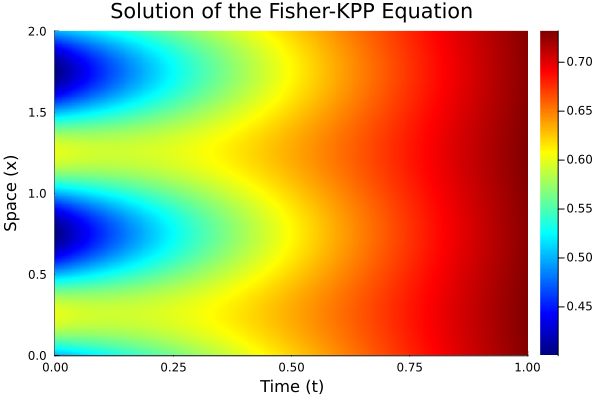

--- Running Advisor Team (Final Scientific Verification) ---
Advisor Status: APPROVED
Advisor Reason: The provided plot visually represents a plausible solution to the Fisher-KPP equation with the specified initial condition and periodic boundary conditions. The initial condition, a sinusoidal wave superimposed on a constant value, is clearly visible at the initial time. As time progresses, the wave visibly propagates and gradually transforms into a smooth, bell-shaped profile characteristic of the Fisher-KPP equation. The periodic boundary conditions are satisfied, as the solution connects smoothly at the domain edges (x=0 and x=2). There are no signs of instability or unphysical oscillations. The overall behavior aligns with the expected evolution of a Fisher-KPP solution, where a localized disturbance propagates and eventually forms a stable, localized profile. The previous feedback trail confirms the code correctly implements the equation, domain, IC, and BCs, further supporting th

In [6]:
max_iterations_all=5
file_content, filename, retrieval_approval, validator_feedback=retrieval_team(
                                                                        user_question,
                                                                        retriever_agent,
                                                                        validator_agent,
                                                                        max_iterations= 5)
if retrieval_approval:
    print('We found a suitable code!')    
    refinement_iterations=0
    is_approved = False
    error_report=''
    while (is_approved == False and refinement_iterations < max_iterations_all):
        print(f"--- Code Creation Iteration: {refinement_iterations} ---")
        file_content, coding_team_approval, last_feedback = code_refinement_team(
                                                                        user_question=user_question,
                                                                        initial_code=file_content,  
                                                                        error_report=error_report,      
                                                                        filename=filename,         
                                                                        patcher_agent=patcher_agent,
                                                                        reviewer_agent=reviewer_agent,
                                                                        max_iterations=5
                                                                    )        
        if coding_team_approval:
            # Running Code:
            project_dir,filename,final_filepath= filing_team(user_question,filename,file_content,naming_agent)
            success,log_file_name=run_code(project_dir,filename,final_filepath)
            # Debugging_team
            status, debugger_report,debug_approval,log_content=debugging_team(user_question,
                                            final_filepath,
                                            log_file_name,
                                            debugger_agent)
            if debug_approval:
                plot_paths = find_plots(project_dir, display_plots=True)
                error_report,is_approved=advisor_team(
                                                    user_question,
                                                    validator_feedback,
                                                    last_feedback,
                                                    debugger_report, 
                                                    plot_paths,
                                                    advisor_agent)
            else:
                error_report=f"Debugger Analysis:\n{debugger_report}\n\n"+f"Log File:\n{log_content}\n\n"
        else:
                print('The coding team did no approve the process.')
                error_report='Lets try again'
        refinement_iterations=refinement_iterations+1
else:
    print('The retrieval process failed.')                                                        